### **Cosmetic** **Data Aquisition Project**

Dataset Description

This dataset contains 1,472 cosmetic and skincare products collected from Kaggle. The dataset includes information on product category, brand, product name, price, product rating, ingredients and suitability for different skin types.This dataset will be combined with additional information collected from the Ulta Beauty website.

Importing the Libraries

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

Reading the csv file

In [ ]:
df = pd.read_csv("cosmetics.csv")

Display the first few lines of code to make sure it is loaded correctly

In [ ]:
df.head()

,Label,Brand,Name,Price,Rank,Ingredients,Combination,Dry,Normal,Oily,Sensitive
0,Moisturizer,LA MER,Crème de la Mer,175,4.1,"Algae (Seaweed) Extract, Mineral Oil, Petrolat...",1,1,1,1,1
1,Moisturizer,SK-II,Facial Treatment Essence,179,4.1,"Galactomyces Ferment Filtrate (Pitera), Butyle...",1,1,1,1,1
2,Moisturizer,DRUNK ELEPHANT,Protini™ Polypeptide Cream,68,4.4,"Water, Dicaprylyl Carbonate, Glycerin, Ceteary...",1,1,1,1,0
3,Moisturizer,LA MER,The Moisturizing Soft Cream,175,3.8,"Algae (Seaweed) Extract, Cyclopentasiloxane, P...",1,1,1,1,1
4,Moisturizer,IT COSMETICS,Your Skin But Better™ CC+™ Cream with SPF 50+,38,4.1,"Water, Snail Secretion Filtrate, Phenyl Trimet...",1,1,1,1,1


Counts the number of products in each category

In [ ]:
df["Label"].value_counts()

,count
Label,
Moisturizer,298
Cleanser,281
Face Mask,266
Treatment,248
Eye cream,209
Sun protect,170


The Largest Category in the Kaggle Dataset was Moisturizer and the smallest category is Sun Protect

Gives the number of products in each brand. Chose random 10

In [ ]:
df["Brand"].value_counts().head(10)

,count
Brand,
CLINIQUE,79
SEPHORA COLLECTION,66
SHISEIDO,63
ORIGINS,54
MURAD,47
PETER THOMAS ROTH,46
KIEHL'S SINCE 1851,46
FRESH,44
DR. JART+,41


The dataset contains a large number of skincare brands. Some brands appear much more frequently than others, suggesting a heavier representation of certain manufacturers.

This shows the no of columns and rows

In [ ]:
df.shape

(1472, 11)

In [ ]:
df.columns

Index(['Label', 'Brand', 'Name', 'Price', 'Rank', 'Ingredients', 'Combination',
       'Dry', 'Normal', 'Oily', 'Sensitive'],
      dtype='object')

The Kaggle dataset contained multiple skincare categories including moisturizers, cleansers, treatments, face masks and eye creams. Equivalent product categories were identified on the Ulta Beauty website and scraped separately to improve compatibility between datasets and increase the likelihood of successful matching.

Display a bar chart to show the distribution of the product ranking across dataset

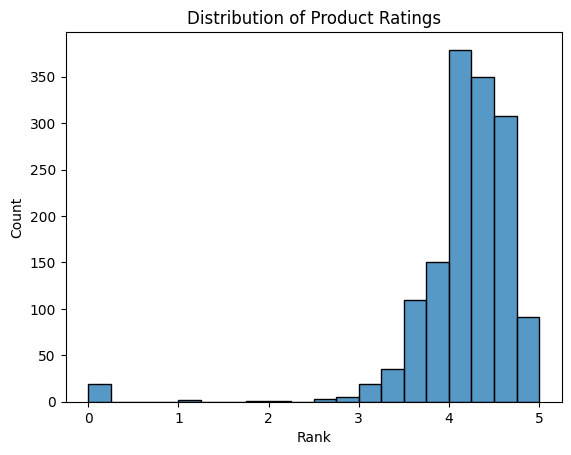

In [ ]:
sns.histplot(df["Rank"], bins=20)

plt.title("Distribution of Product Ratings")
plt.show()

Most products achieved ratings above 4.0, indicating generally positive customer evaluations.

## **Scraping Moisturizers**


Importing python library used for web scraping

In [ ]:
import requests
from bs4 import BeautifulSoup
import re
import pandas as pd

This code is used to connect to the Ulta Beauty moisturiser webpage and check whether Python can access it

In [ ]:
url = "https://www.ulta.com/shop/skin-care/moisturizers"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


This code is used to extract product information from the Ulta Beauty webpage using Regular Expressions

In [ ]:
ratings = re.findall(
    r'"rating":(.*?),',
    response.text
)

print(ratings[:10])
print(len(ratings))

reviews = re.findall(
    r'"reviewCount":(.*?),',
    response.text
)

print(reviews[:10])
print(len(reviews))

names = re.findall(
    r'"productName":"(.*?)"',
    response.text
)

print(names[:20])
print(len(names))

brands = re.findall(
    r'"brandName":"(.*?)"',
    response.text
)

print(brands[:20])
print(len(brands))

prices = re.findall(
    r'"listPrice":"(.*?)"',
    response.text
)

print(prices[:20])
print(len(prices))

['4.6', '3.9', '4', '4.5', '4.6', '4.4', '4.5', '4.7', '4.4', '4.7']
64
['44674', '104', '2026', '3835', '1250', '8600', '931', '4958', '4812', '3118']
64
['Moisture Surge 100H Auto-Replenishing Hydrator Gel Moisturizer with Hyaluronic Acid', '345 Relief Cream', 'Toleriane Double Repair Face Moisturizer with Niacinamide', 'Do It All Hydrating Sheer Tinted Moisturizer Balm', 'The Dewy Skin Cream Line-Plumping Moisturizer', 'COMPLEXION RESCUE Tinted Moisturizer with Hyaluronic Acid and Mineral SPF 30', 'Pout Preserve Hydrating Peptide Lip Treatment', 'Vitamin Enriched Face Base+ Moisturizer & Primer with Vitamin C + Hyaluronic Acid', 'CC+ Nude Glow Lightweight Foundation + Glow Serum with SPF 40', 'Cicaplast Balm B5 Soothing Therapeutic Multi Purpose Cream', 'PDRN Hyaluronic Acid 100 Moisturizing Cream', 'Dramatically Different Moisturizing Lotion+Â\xa0For Face', 'Glow Reviver Melting Lip Balm', 'Toleriane Double Repair Face Moisturizer UV SPF 30', 'Halo Glow Liquid Filter', 'Hueguard Sk

This code uses BeautifulSoup to analyse the HTML structure of the Ulta Beauty webpage and extract its page title

In [ ]:
soup = BeautifulSoup(response.text, "html.parser")

print(soup.title)

<title data-rh="true">Moisturizers - Skin Care - 2236 Products | Ulta Beauty</title>


This code creates a Pandas DataFrame using the product information you previously extracted from the Ulta Beauty website

In [ ]:
moisturizer_df = pd.DataFrame({
    "Brand": brands,
    "Name": names,
    "Ulta_Rating": ratings,
    "Ulta_Review_Count": reviews,
    "Ulta_Price_range": prices
})

This code adds a new column called Label to your dataset and assigns the value "Moisturiser" to every row.

In [ ]:
moisturizer_df["Label"] = "Moisturiser"

In [ ]:
moisturizer_df.head()

,Brand,Name,Ulta_Rating,Ulta_Review_Count,Ulta_Price_range,Label
0,Clinique,Moisture Surge 100H Auto-Replenishing Hydrator...,4.6,44674,$18.00 - $89.00,Moisturiser
1,Dr. Althea,345 Relief Cream,3.9,104,$27.00,Moisturiser
2,La Roche-Posay,Toleriane Double Repair Face Moisturizer with ...,4,2026,$12.99 - $25.99,Moisturiser
3,IT Cosmetics,Do It All Hydrating Sheer Tinted Moisturizer Balm,4.5,3835,$34.00,Moisturiser
4,TATCHA,The Dewy Skin Cream Line-Plumping Moisturizer,4.6,1250,$25.00 - $93.00,Moisturiser


This code saves your collected Ulta Beauty moisturiser dataset as a CSV file

In [ ]:
moisturizer_df.to_csv(
    "ulta_moisturizer.csv",
    index=False
)

### **Scraping** **Cleansers**

In [ ]:
url = "https://www.ulta.com/shop/skin-care/cleansers"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


In [ ]:
ratings = re.findall(
    r'"rating":(.*?),',
    response.text
)

print(ratings[:10])
print(len(ratings))

reviews = re.findall(
    r'"reviewCount":(.*?),',
    response.text
)

print(reviews[:10])
print(len(reviews))

names = re.findall(
    r'"productName":"(.*?)"',
    response.text
)

print(names[:20])
print(len(names))

brands = re.findall(
    r'"brandName":"(.*?)"',
    response.text
)

print(brands[:20])
print(len(brands))

prices = re.findall(
    r'"listPrice":"(.*?)"',
    response.text
)

print(prices[:20])
print(len(prices))

['4.2', '3.9', '4.6', '4.6', '4.4', '4.6', '4.6', '4.2', '4.4', '4.7']
64
['2172', '210', '3340', '44675', '2698', '44675', '151', '456', '740', '4680']
64
['Glycolic Acid 7% Exfoliating and Brightening Daily Toner', 'Zero Pore Pad', 'Toleriane Purifying Foaming Face Wash for Oily Skin', 'Take The Day Off Cleansing Balm Makeup Remover', 'Toleriane Hydrating Gentle Face Cleanser for Dry Skin', 'Take The Day Off Makeup Remover For Lids, Lashes & Lips', 'PDRN Hyaluronic Acid Hydrating Capsule Mist', 'Hydrating Milky Toner', 'Heartleaf Quercetinol Pore Deep Cleansing Foam', 'Special Cleansing Gel', 'Heartleaf Pore Control Cleansing Oil', 'Clarifying Face Lotion Toner 2 - Dry Combination', 'The Rice Wash Skin-Softening Cleanser', 'Clean Towels Original Disposable Face Towels', 'Kojic Acid Turmeric Pad', 'Foaming Facial Cleanser', 'Rice 70 Glow Milky Toner', 'Precleanse Cleansing Oil', 'Bi-Facil Double Action Eye Makeup Remover', 'Purity Made Simple One-Step Facial Cleanser']
64
['The Ordina

In [ ]:
cleanser_df = pd.DataFrame({
    "Brand": brands,
    "Name": names,
    "Ulta_Rating": ratings,
    "Ulta_Review_Count": reviews,
    "Ulta_Price_range": prices
})

In [ ]:
cleanser_df["Label"] = "Cleanser"

In [ ]:
cleanser_df.head()

,Brand,Name,Ulta_Rating,Ulta_Review_Count,Ulta_Price_range,Label
0,The Ordinary,Glycolic Acid 7% Exfoliating and Brightening D...,4.2,2172,$9.00 - $13.50,Cleanser
1,medicube,Zero Pore Pad,3.9,210,$21.00,Cleanser
2,La Roche-Posay,Toleriane Purifying Foaming Face Wash for Oily...,4.6,3340,$16.99 - $19.99,Cleanser
3,Clinique,Take The Day Off Cleansing Balm Makeup Remover,4.6,44675,$15.00 - $58.00,Cleanser
4,La Roche-Posay,Toleriane Hydrating Gentle Face Cleanser for D...,4.4,2698,$9.99 - $21.99,Cleanser


In [ ]:
cleanser_df.to_csv(
    "ulta_Cleanser.csv",
    index=False
)

### **Scraping Eye Creams**


In [ ]:
url = "https://www.ulta.com/shop/skin-care/eye-treatments/eye-cream"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


In [ ]:
ratings = re.findall(
    r'"rating":(.*?),',
    response.text
)

print(ratings[:10])
print(len(ratings))

reviews = re.findall(
    r'"reviewCount":(.*?),',
    response.text
)

print(reviews[:10])
print(len(reviews))

names = re.findall(
    r'"productName":"(.*?)"',
    response.text
)

print(names[:20])
print(len(names))

brands = re.findall(
    r'"brandName":"(.*?)"',
    response.text
)

print(brands[:20])
print(len(brands))

prices = re.findall(
    r'"listPrice":"(.*?)"',
    response.text
)

print(prices[:20])
print(len(prices))

['4.6', '4.6', '4.6', '4.6', '3.4', '4.5', '4.4', '4.5', '4.3', '4.5']
64
['44675', '117', '5685', '44674', '50', '1296', '5621', '109', '886', '5774']
64
['All About Eyes Eye Cream with Vitamin C', 'Lacto-PDRN 4% + B9 Eye Cream', 'Luminous Eye Corrector SPF 41', 'Clinique Smart Clinical Repair Wrinkle Correcting Eye Cream', 'Calcium Volume Multi Balm', 'All About Eyes Rich Eye Cream with Hyaluronic Acid', 'Total Eye Lift Refillable Eye Cream', 'PDRN Caffeine Rejuvenating Eye Cream', 'Creamy Eye Treatment with Avocado', 'â\x80\x98Spresso Energizing Eye Balm', 'Yerba Mate Wake Up Eye Gel', 'Advanced Night Repair Eye Lift + Sculpt Eye Cream', 'Derm Correxion Eye Repair Dark Circle Eye Cream', 'Benefiance Wrinkle Smoothing Eye Cream', 'Banana Bright+ Vitamin C Eye CrÃ¨me for Dark Circles', 'Confidence in an Eye Cream Anti-Aging Peptide Eye Cream', 'Firming Peptide Eye Cream', 'Advanced Night Repair Eye Gel-Cream for Dark Circles', 'Pure Radiance Brightening Eye Cream', 'Phyto Nature Lifti

In [ ]:
EyeCream_df = pd.DataFrame({
    "Brand": brands,
    "Name": names,
    "Ulta_Rating": ratings,
    "Ulta_Review_Count": reviews,
    "Ulta_Price_range": prices
})

In [ ]:
EyeCream_df["Label"] = "EyeCream"

In [ ]:
EyeCream_df.head()

,Brand,Name,Ulta_Rating,Ulta_Review_Count,Ulta_Price_range,Label
0,Clinique,All About Eyes Eye Cream with Vitamin C,4.6,44675,$39.00 - $66.00,EyeCream
1,The Ordinary,Lacto-PDRN 4% + B9 Eye Cream,4.6,117,$9.50,EyeCream
2,DRMTLGY,Luminous Eye Corrector SPF 41,4.6,5685,$44.00,EyeCream
3,Clinique,Clinique Smart Clinical Repair Wrinkle Correct...,4.6,44674,$66.00 - $100.00,EyeCream
4,Dr. Melaxin,Calcium Volume Multi Balm,3.4,50,$19.00,EyeCream


In [ ]:
EyeCream_df.to_csv(
    "ulta_EyeCream.csv",
    index=False
)

# **Scraping Face Masks**

In [ ]:
url = "https://www.ulta.com/shop/skin-care/treatment-serums/face-masks"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


In [ ]:
ratings = re.findall(
    r'"rating":(.*?),',
    response.text
)

print(ratings[:10])
print(len(ratings))

reviews = re.findall(
    r'"reviewCount":(.*?),',
    response.text
)

print(reviews[:10])
print(len(reviews))

names = re.findall(
    r'"productName":"(.*?)"',
    response.text
)

print(names[:20])
print(len(names))

brands = re.findall(
    r'"brandName":"(.*?)"',
    response.text
)

print(brands[:20])
print(len(brands))

prices = re.findall(
    r'"listPrice":"(.*?)"',
    response.text
)

print(prices[:20])
print(len(prices))

['3.7', '3.8', '4.6', '3.7', '3.8', '4.7', '4.4', '4.7', '4.6', '4.3']
64
['102', '129', '448', '58', '13', '959', '241', '89', '1051', '570']
64
['PDRN Pink Collagen Gel Mask', 'Collagen Night Wrapping Mask', 'Smart Clinical Repair Overnight Recovery Face Cream + Mask', 'Kojic Acid Turmeric Night Wrapping Mask', 'Kojic Acid Turmeric Gel Mask', 'Moisture Surge Overnight Face Mask', 'Bio-Collagen Radiance Facial Mask', 'Deep Collagen Power Boosting Overnight Sheet Mask', 'The POREfessional Deep Retreat Pore-Clearing Clay Mask', 'Salicylic Acid 2% Masque Clarifying Charcoal & Clay Mask for Blemish Prone Skin', 'Madagascar Centella Poremizing Quick Clay Stick Mask', 'Peanuts x UBC Face Mask Set', 'Pumpkin Enzyme Clarifying Mask', 'Advanced Snail Mucin Glass Glow Hydrogel Mask', 'PDRN Exosome Skinplaning Glaze Mask with Collagen & Peptide', 'Mask Melt PDRN + Hyaluronic Acid Overnight Hydrogel Mask', 'Mask Melt Collagen + Peptide Overnight Hydrogel Mask', 'Clear Improvement Active Charcoal 

In [ ]:
FaceMask_df = pd.DataFrame({
    "Brand": brands,
    "Name": names,
    "Ulta_Rating": ratings,
    "Ulta_Review_Count": reviews,
    "Ulta_Price_range": prices
})

In [ ]:
FaceMask_df["Label"] = "FaceMask"

In [ ]:
FaceMask_df.head()

,Brand,Name,Ulta_Rating,Ulta_Review_Count,Ulta_Price_range,Label
0,medicube,PDRN Pink Collagen Gel Mask,3.7,102,$19.90,FaceMask
1,medicube,Collagen Night Wrapping Mask,3.8,129,$20.90,FaceMask
2,Clinique,Smart Clinical Repair Overnight Recovery Face ...,4.6,448,$83.00,FaceMask
3,medicube,Kojic Acid Turmeric Night Wrapping Mask,3.7,58,$20.90,FaceMask
4,medicube,Kojic Acid Turmeric Gel Mask,3.8,13,$19.90,FaceMask


In [ ]:
FaceMask_df.to_csv(
    "ulta_FaceMask.csv",
    index=False
)

### **Scraping Sun protect**

In [ ]:
url = "https://www.ulta.com/shop/body-care/suncare/sunscreen"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


In [ ]:
ratings = re.findall(
    r'"rating":(.*?),',
    response.text
)

print(ratings[:10])
print(len(ratings))

reviews = re.findall(
    r'"reviewCount":(.*?),',
    response.text
)

print(reviews[:10])
print(len(reviews))

names = re.findall(
    r'"productName":"(.*?)"',
    response.text
)

print(names[:20])
print(len(names))

brands = re.findall(
    r'"brandName":"(.*?)"',
    response.text
)

print(brands[:20])
print(len(brands))

prices = re.findall(
    r'"listPrice":"(.*?)"',
    response.text
)

print(prices[:20])
print(len(prices))

['4.7', '4.6', '4.3', '4.5', '4.5', '4.5', '4.7', '4.9', '4.5', '4.1']
64
['1109', '5685', '2657', '3792', '259', '1799', '933', '298', '329', '2086']
64
['Unseen Sunscreen SPF 50 Invisible Sun Protection', 'Luminous Eye Corrector SPF 41', 'Anthelios Mineral Tinted Ultra Light Face Sunscreen Fluid SPF 50', 'Glowscreen SPF 40 Sunscreen with Hyaluronic Acid + Niacinamide', 'Zero-Cast Moisturizing Finish Sunscreen', 'Mineral Mattescreen SPF 40', 'Madagascar Centella Hyalu-Cica Water-Fit Sun Serum UV SPF50', 'The Milky Sunscreen SPF 50+ PA++++', 'Toleriane Double Repair Matte Face Moisturizer with SPF30', 'Anthelios Clear Skin Dry Touch Face Sunscreen SPF 60', 'Moisturizing Sunscreen Lotion SPF 30', 'Anthelios Ultra Light Fluid Face Sunscreen SPF 60', 'Dramatically Different Moisturizing Lotion+ SPF35 for Face', 'UV Filters SPF 45 Serum', 'Anthelios UV Air Daily Supercharged Serum Sunscreen SPF 50', 'Anthelios Mineral Ultra-Light Face Sunscreen Fluid SPF 50', 'Birch Juice Moisturizing UVLO

In [ ]:
SunProtect_df = pd.DataFrame({
    "Brand": brands,
    "Name": names,
    "Ulta_Rating": ratings,
    "Ulta_Review_Count": reviews,
    "Ulta_Price_range": prices
})

In [ ]:
SunProtect_df["Label"] = "Sun protect"

In [ ]:
SunProtect_df.head()

,Brand,Name,Ulta_Rating,Ulta_Review_Count,Ulta_Price_range,Label
0,Supergoop!,Unseen Sunscreen SPF 50 Invisible Sun Protection,4.7,1109,$19.00 - $48.00,Sun protect
1,DRMTLGY,Luminous Eye Corrector SPF 41,4.6,5685,$44.00,Sun protect
2,La Roche-Posay,Anthelios Mineral Tinted Ultra Light Face Suns...,4.3,2657,$39.99,Sun protect
3,Supergoop!,Glowscreen SPF 40 Sunscreen with Hyaluronic Ac...,4.5,3792,$38.00,Sun protect
4,ANUA,Zero-Cast Moisturizing Finish Sunscreen,4.5,259,$18.00,Sun protect


In [ ]:
SunProtect_df.to_csv(
    "ulta_SunProtect.csv",
    index=False
)

### **Scraping Treatment**

In [ ]:
url = "https://www.ulta.com/shop/skin-care/treatment-serums"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


In [ ]:
ratings = re.findall(
    r'"rating":(.*?),',
    response.text
)

print(ratings[:10])
print(len(ratings))

reviews = re.findall(
    r'"reviewCount":(.*?),',
    response.text
)

print(reviews[:10])
print(len(reviews))

names = re.findall(
    r'"productName":"(.*?)"',
    response.text
)

print(names[:20])
print(len(names))

brands = re.findall(
    r'"brandName":"(.*?)"',
    response.text
)

print(brands[:20])
print(len(brands))

prices = re.findall(
    r'"listPrice":"(.*?)"',
    response.text
)

print(prices[:20])
print(len(prices))

['4.3', '4.6', '4.7', '4.7', '4.7', '3', '3.7', '4.2', '4.5', '4.5']
64
['1329', '413', '5625', '3118', '5511', '54', '102', '6002', '22182', '812']
64
['Hyaluronic Acid 2% + B5 Hydrating Serum with Ceramides', 'Azelaic Acid 10 Hyaluron Redness Soothing Serum', 'Mighty Patch Original Acne Pimple Patches', 'Cicaplast Balm B5 Soothing Therapeutic Multi Purpose Cream', 'Daily Microfoliant Exfoliator', 'PDRN Pink Collagen Volume Multi Balm', 'PDRN Pink Collagen Gel Mask', 'Niacinamide 10% + Zinc 1% Serum for Oily Skin', 'Advanced Night Repair Multi-Recovery Complex Serum with Hyaluronic Acid & Peptides', 'Niacinamide 10 TXA 4 Serum for Brightening and Dark Spots', 'Glass Skin Ginseng Collagen Mask', 'Azelaic Acid Suspension 10% Cream for Redness and Blemish-Prone Skin', 'DOUBLE SERUM Age-Defying Concentrate', 'Multi-Peptide + Copper Peptides 1% for Wrinkles and Skin Elasticity', 'Clinique Smart Clinical Repair Wrinkle Correcting Serum', 'Hyalu B5 Pure Hyaluronic Acid Face Serum', 'Discolor

In [ ]:
Treatment_df = pd.DataFrame({
    "Brand": brands,
    "Name": names,
    "Ulta_Rating": ratings,
    "Ulta_Review_Count": reviews,
    "Ulta_Price_range": prices
})

In [ ]:
Treatment_df["Label"] = "Treatment"

In [ ]:
Treatment_df.head()

,Brand,Name,Ulta_Rating,Ulta_Review_Count,Ulta_Price_range,Label
0,The Ordinary,Hyaluronic Acid 2% + B5 Hydrating Serum with C...,4.3,1329,$9.90 - $31.50,Treatment
1,ANUA,Azelaic Acid 10 Hyaluron Redness Soothing Serum,4.6,413,$22.00,Treatment
2,Hero Cosmetics,Mighty Patch Original Acne Pimple Patches,4.7,5625,$8.99 - $21.99,Treatment
3,La Roche-Posay,Cicaplast Balm B5 Soothing Therapeutic Multi P...,4.7,3118,$20.99 - $32.99,Treatment
4,Dermalogica,Daily Microfoliant Exfoliator,4.7,5511,$19.50 - $69.00,Treatment


In [ ]:
Treatment_df.to_csv(
    "ulta_treatment.csv",
    index=False
)

Merge All these datatset

Combines six separate Ulta Beauty skincare datasets into one larger dataset using Pandas.

In [ ]:
ulta_df = pd.concat([
    moisturizer_df,
    cleanser_df,
    EyeCream_df,
    FaceMask_df,
    Treatment_df,
    SunProtect_df
], ignore_index=True)

In [ ]:
ulta_df.shape

(384, 6)

In [ ]:
ulta_df.head()

,Brand,Name,Ulta_Rating,Ulta_Review_Count,Ulta_Price_range,Label
0,Clinique,Moisture Surge 100H Auto-Replenishing Hydrator...,4.6,44674,$18.00 - $89.00,Moisturiser
1,Dr. Althea,345 Relief Cream,3.9,104,$27.00,Moisturiser
2,La Roche-Posay,Toleriane Double Repair Face Moisturizer with ...,4,2026,$12.99 - $25.99,Moisturiser
3,IT Cosmetics,Do It All Hydrating Sheer Tinted Moisturizer Balm,4.5,3835,$34.00,Moisturiser
4,TATCHA,The Dewy Skin Cream Line-Plumping Moisturizer,4.6,1250,$25.00 - $93.00,Moisturiser


In [ ]:
ulta_df.to_csv("Full_Ulta_Dataset.csv", index=False)

Merge Strategy

The Kaggle dataset and Ulta dataset were compared using Brand and product category information. Initially a merge was attempted using Brand alone; however this produced inaccurate matches because a single brand often sells multiple products within a category.

A second merge approach was used to improve matching accuracy. Although only a small number of exact matches were identified, the exercise demonstrated the challenges associated with integrating datasets from different sources.

In [ ]:
merged_df = pd.merge(
    df,
    ulta_df,
    on=["Brand", "Label"],
    how="left"
)

print(merged_df.shape)
merged_df.head()

(1482, 15)


,Label,Brand,Name_x,Price,Rank,Ingredients,Combination,Dry,Normal,Oily,Sensitive,Name_y,Ulta_Rating,Ulta_Review_Count,Ulta_Price_range
0,Moisturizer,LA MER,Crème de la Mer,175,4.1,"Algae (Seaweed) Extract, Mineral Oil, Petrolat...",1,1,1,1,1,NaN,NaN,NaN,NaN
1,Moisturizer,SK-II,Facial Treatment Essence,179,4.1,"Galactomyces Ferment Filtrate (Pitera), Butyle...",1,1,1,1,1,NaN,NaN,NaN,NaN
2,Moisturizer,DRUNK ELEPHANT,Protini™ Polypeptide Cream,68,4.4,"Water, Dicaprylyl Carbonate, Glycerin, Ceteary...",1,1,1,1,0,NaN,NaN,NaN,NaN
3,Moisturizer,LA MER,The Moisturizing Soft Cream,175,3.8,"Algae (Seaweed) Extract, Cyclopentasiloxane, P...",1,1,1,1,1,NaN,NaN,NaN,NaN
4,Moisturizer,IT COSMETICS,Your Skin But Better™ CC+™ Cream with SPF 50+,38,4.1,"Water, Snail Secretion Filtrate, Phenyl Trimet...",1,1,1,1,1,NaN,NaN,NaN,NaN


Creates a new dataset containing only the products that successfully matched with Ulta Beauty ratings.

In [ ]:
matched_df = merged_df[
    merged_df["Ulta_Rating"].notnull()
]

matched_df.shape

(20, 15)

In [ ]:
matched_df.head()

,Label,Brand,Name_x,Price,Rank,Ingredients,Combination,Dry,Normal,Oily,Sensitive,Name_y,Ulta_Rating,Ulta_Review_Count,Ulta_Price_range
301,Cleanser,FARMACY,Green Clean Makeup Meltaway Cleansing Balm wit...,34,4.6,"Cetyl Ethylhexanoate, Caprylic/Capric Triglyce...",1,1,1,1,1,Green Clean Cleansing Balm,4.9,2668,$39.00
305,Cleanser,TATCHA,The Rice Polish Foaming Enzyme Powder,65,4.4,"Microcrystalline Cellulose, Oryza Sativa (Rice...",1,1,1,1,1,The Rice Wash Skin-Softening Cleanser,4.5,80,$19.00 - $59.00
306,Cleanser,TATCHA,The Rice Polish Foaming Enzyme Powder,65,4.4,"Microcrystalline Cellulose, Oryza Sativa (Rice...",1,1,1,1,1,The Matcha Foam Pore-Refining & Oil-Balancing ...,4.9,463,$19.00 - $40.00
307,Cleanser,TATCHA,The Rice Polish Foaming Enzyme Powder,65,4.4,"Microcrystalline Cellulose, Oryza Sativa (Rice...",1,1,1,1,1,Dewy Skin To Go Set,5,1,$69.00
312,Cleanser,TATCHA,The Deep Cleanse,38,4.4,* Hadasei-3,1,0,1,1,1,The Rice Wash Skin-Softening Cleanser,4.5,80,$19.00 - $59.00


In [ ]:
merged_df.to_csv(
    "merged_data.csv",
    index=False
)

Limitations of the Merge

The Kaggle and Ulta datasets contained different product catalogues. Although common fields such as Brand and Label were available, many products did not have exact matches between datasets. As a result, only a small subset of products could be successfully linked.

This highlights a common challenge in real-world data integration, where datasets from different sources often use different product ranges, naming conventions and levels of detail.

Displayed the matched products

In [ ]:
matched_df

,Label,Brand,Name_x,Price,Rank,Ingredients,Combination,Dry,Normal,Oily,Sensitive,Name_y,Ulta_Rating,Ulta_Review_Count,Ulta_Price_range
301,Cleanser,FARMACY,Green Clean Makeup Meltaway Cleansing Balm wit...,34,4.6,"Cetyl Ethylhexanoate, Caprylic/Capric Triglyce...",1,1,1,1,1,Green Clean Cleansing Balm,4.9,2668,$39.00
305,Cleanser,TATCHA,The Rice Polish Foaming Enzyme Powder,65,4.4,"Microcrystalline Cellulose, Oryza Sativa (Rice...",1,1,1,1,1,The Rice Wash Skin-Softening Cleanser,4.5,80,$19.00 - $59.00
306,Cleanser,TATCHA,The Rice Polish Foaming Enzyme Powder,65,4.4,"Microcrystalline Cellulose, Oryza Sativa (Rice...",1,1,1,1,1,The Matcha Foam Pore-Refining & Oil-Balancing ...,4.9,463,$19.00 - $40.00
307,Cleanser,TATCHA,The Rice Polish Foaming Enzyme Powder,65,4.4,"Microcrystalline Cellulose, Oryza Sativa (Rice...",1,1,1,1,1,Dewy Skin To Go Set,5,1,$69.00
312,Cleanser,TATCHA,The Deep Cleanse,38,4.4,* Hadasei-3,1,0,1,1,1,The Rice Wash Skin-Softening Cleanser,4.5,80,$19.00 - $59.00
313,Cleanser,TATCHA,The Deep Cleanse,38,4.4,* Hadasei-3,1,0,1,1,1,The Matcha Foam Pore-Refining & Oil-Balancing ...,4.9,463,$19.00 - $40.00
314,Cleanser,TATCHA,The Deep Cleanse,38,4.4,* Hadasei-3,1,0,1,1,1,Dewy Skin To Go Set,5,1,$69.00
366,Cleanser,FARMACY,Clean Bee Ultra Gentle Facial Cleanser,28,4.3,"Water, Sodium Lauroyl Methyl Isethionate, Coca...",1,1,1,1,1,Green Clean Cleansing Balm,4.9,2668,$39.00
451,Cleanser,TATCHA,Aburatorigami Japanese Blotting Papers,12,4.7,"Abaca Leaf, Gold Flakes.",1,1,1,1,1,The Rice Wash Skin-Softening Cleanser,4.5,80,$19.00 - $59.00
452,Cleanser,TATCHA,Aburatorigami Japanese Blotting Papers,12,4.7,"Abaca Leaf, Gold Flakes.",1,1,1,1,1,The Matcha Foam Pore-Refining & Oil-Balancing ...,4.9,463,$19.00 - $40.00


## Data Quality Issues

There were some challenges during data integration



1.   Product names were often varying between datasets
2.   Some brands available in the Kaggle Dataset were not available in the scraped Ulta Categories

1.   Product Descriptions varied across sources
2.   The Merge therefore resulted in very few successful matches





Dataset Merging

The Kaggle cosmetics dataset and the Ulta Beauty dataset were merged using the variables Brand and Label.
Prior to merging, category labels were standardized to ensure consistency between datasets.
Some brands appeared in both datasets, allowing successful matches to be created.

Challenges Encountered

A relatively small number of exact matches were found.
Many products available on Ulta were not present in the Kaggle dataset and vice versa.
Differences in brand naming conventions, product ranges, and category labels reduced the number of successful matches.

Data Quality

Missing values were present after the merge because not every Kaggle product had a corresponding Ulta product.
These unmatched records were retained using a left join to preserve the integrity of the original dataset.

Implications

The limited number of matches suggests that the two datasets represent different product selections.
Results based on matched products should therefore be interpreted cautiously.
Despite the low match rate, the merged dataset still provides useful insights into how customer ratings and review activity compare across sources.

Visualisation 1: Average Ulta Rating by Product Category

Purpose: To compare customer satisfaction across skincare categories.

Findings: All categories achieved relatively high average ratings above 4.5 out of 5. Cleansers recorded the highest average rating, followed by Sun Protection and Treatment products. The differences between categories are relatively small.

Interpretation: The consistently high ratings indicate a generally positive customer experience across skincare categories. The slightly higher rating for cleansers may suggest that consumers perceive cleansing products as easier to evaluate and more likely to produce immediate results compared with treatment-based products.

In [ ]:
matched_df["Ulta_Rating"] = pd.to_numeric(
    matched_df["Ulta_Rating"],
    errors="coerce"
)

matched_df["Ulta_Review_Count"] = pd.to_numeric(
    matched_df["Ulta_Review_Count"],
    errors="coerce"
)

/tmp/ipykernel_417/1705911223.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  matched_df["Ulta_Rating"] = pd.to_numeric(
/tmp/ipykernel_417/1705911223.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  matched_df["Ulta_Review_Count"] = pd.to_numeric(


/tmp/ipykernel_417/641150962.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


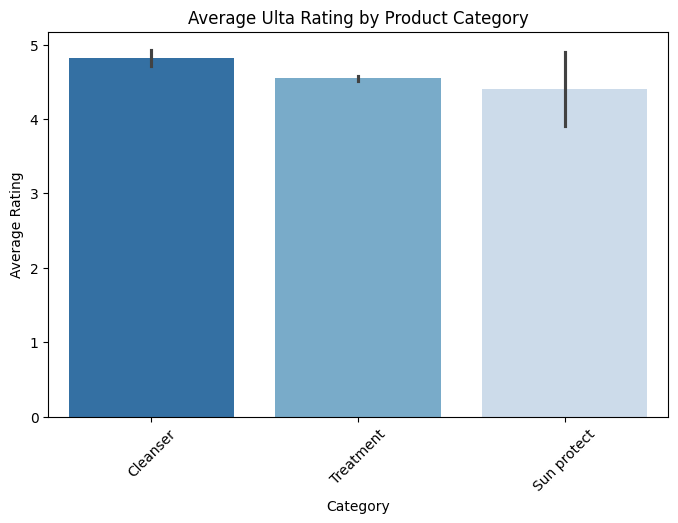

In [ ]:
plt.figure(figsize=(8,5))

order = matched_df.groupby("Label")["Ulta_Rating"]\
           .mean()\
           .sort_values(ascending=False)\
           .index

sns.barplot(
    data=matched_df,
    x="Label",
    y="Ulta_Rating",
    order=order,
    palette="Blues_r"
)

plt.title("Average Ulta Rating by Product Category")
plt.xlabel("Category")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.show()

Visualisation 2: Distribution of Product Prices
Better Analysis

Purpose: To understand the pricing structure of skincare products in the dataset.

Findings: Most products are concentrated within the lower-to-middle price ranges. The distribution is right-skewed, with relatively few products occupying premium price points above $100.

Interpretation: The skincare market represented in the dataset appears to be dominated by products targeting mass-market consumers rather than luxury buyers. Premium products exist but represent a much smaller proportion of available offerings.

Conclusion: The dataset is primarily composed of affordable and moderately priced products, which reflects broader consumer demand within the skincare industry.

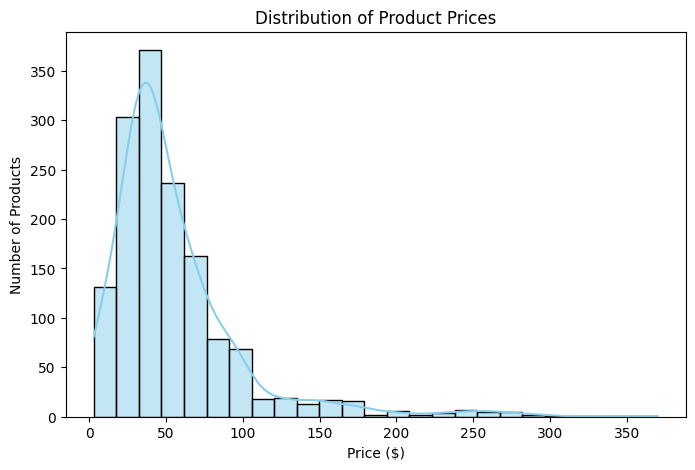

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["Price"],
    bins=25,
    kde=True,
    color="skyblue"
)

plt.title("Distribution of Product Prices")
plt.xlabel("Price ($)")
plt.ylabel("Number of Products")

plt.show()

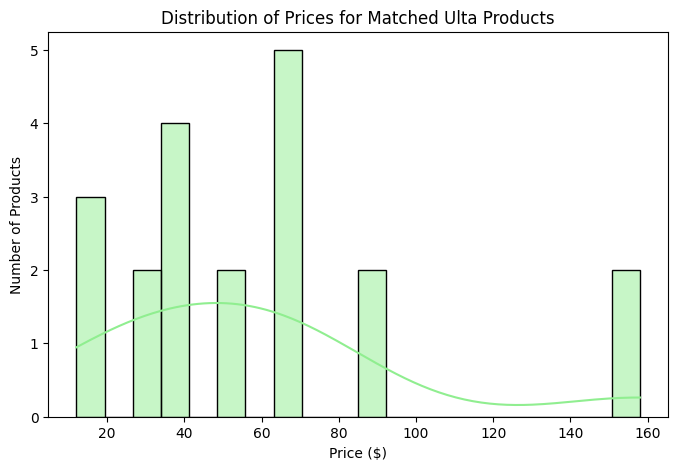

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(
    matched_df["Price"],
    bins=20,
    kde=True,
    color="lightgreen"
)

plt.title("Distribution of Prices for Matched Ulta Products")
plt.xlabel("Price ($)")
plt.ylabel("Number of Products")

plt.show()

Visualisation 4: Kaggle Rating vs Ulta Rating
Better Analysis

Purpose: To examine whether products receiving higher ratings in the Kaggle dataset also receive higher ratings from Ulta customers.

Findings: The points are scattered across the plot without forming a clear upward trend. Products with similar Kaggle ratings often have different Ulta ratings.

Interpretation: The absence of a strong relationship suggests that ratings may be influenced by different audiences, review methodologies, and product selections across the two sources.

Conclusion: Ratings from one platform cannot reliably predict ratings on the other platform, highlighting differences between customer evaluation systems.

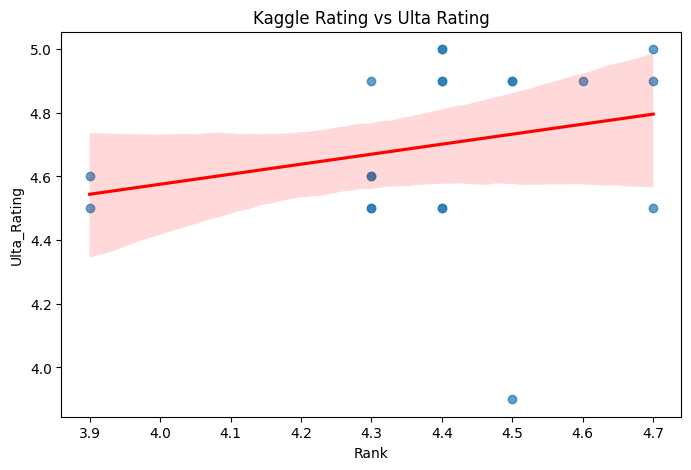

In [ ]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=matched_df,
    x="Rank",
    y="Ulta_Rating",
    scatter_kws={"alpha":0.7},
    line_kws={"color":"red"}
)

plt.title("Kaggle Rating vs Ulta Rating")

plt.show()

Visualisation 5: Product Price vs Ulta Review Count
A scatter plot was used to investigate the relationship between product prices and the number of customer reviews in the Ulta dataset. The x-axis represents product prices in US dollars, while the y-axis represents the number of customer reviews. The visualisation shows that products across different price ranges received varying numbers of reviews. Some lower-priced products attracted a high number of customer reviews, while certain higher-priced products also received substantial engagement. However, there does not appear to be a clear relationship between product price and review count. This suggests that more expensive products do not necessarily receive more customer reviews than cheaper alternatives.

What this tells us: Product popularity, measured by the number of customer reviews, does not appear to depend directly on price. Other factors, such as brand recognition, product quality and customer demand, may influence the number of reviews a product receives.

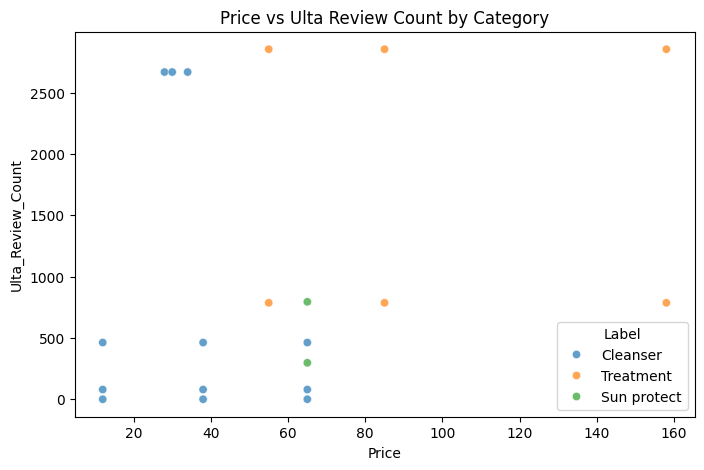

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=matched_df,
    x="Price",
    y="Ulta_Review_Count",
    hue="Label",
    alpha=0.7
)

plt.title("Price vs Ulta Review Count by Category")

plt.show()

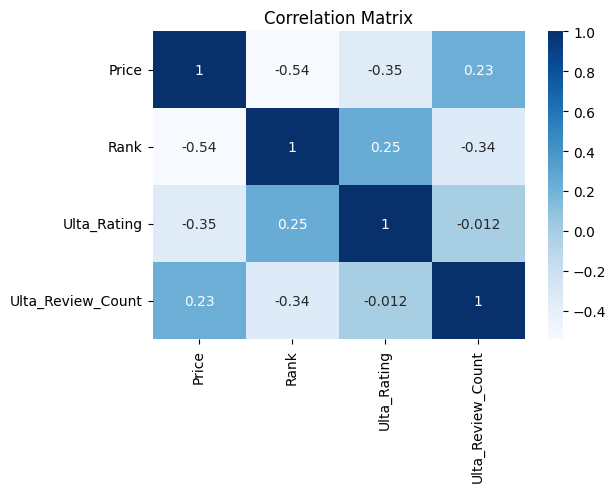

In [ ]:
corr_data = matched_df[
    ["Price",
     "Rank",
     "Ulta_Rating",
     "Ulta_Review_Count"]
].corr()

plt.figure(figsize=(6,4))

sns.heatmap(
    corr_data,
    annot=True,
    cmap="Blues"
)

plt.title("Correlation Matrix")
plt.show()

Variables	Correlation	Interpretation

Price vs Rank	-0.54
Moderate negative relationship. Higher-priced products tend to have better ranks (assuming lower rank number = better rank).

Price vs Ulta_Rating -0.35
Weak to moderate negative relationship. More expensive products tend to have slightly lower ratings.

Price vs Ulta_Review_Count	0.23
Very weak positive relationship. More expensive products have slightly more reviews, but the relationship is weak.

Rank vs Ulta_Rating	0.25
Weak positive relationship. Rank and rating have only a small connection.

Rank vs Ulta_Review_Count	-0.34
Weak negative relationship. Products with more reviews tend to have somewhat better ranks.

Ulta_Rating vs Ulta_Review_Count	-0.012
Essentially no relationship. Rating and review count are almost completely unrelated in your matched dataset.

Overall Findings

1. Customer ratings are consistently high across skincare categories
 (Bar Chart: Average Rating by Category)
 Most skincare categories achieved average ratings above 4 out of 5, indicating generally high customer satisfaction.

2. Customer engagement varies across skincare categories
 (Bar Chart: Average Review Count by Category)
 Some categories received substantially more reviews than others, suggesting differences in product popularity and customer engagement.

3. Product popularity does not necessarily indicate higher ratings
 (Scatter Plot: Review Count vs Rating)
 Products with large numbers of reviews did not consistently achieve higher ratings, suggesting popularity and satisfaction are not strongly linked.

4. Product price has a weak relationship with customer ratings
 (Scatter Plot: Price vs Rating)
 Higher-priced products were not consistently rated more highly than lower-priced products.

5. Product price has a weak relationship with customer engagement
 (Scatter Plot: Price vs Review Count)
 Products across all price ranges received varying levels of customer engagement, indicating that factors beyond price influence review activity.

6. Kaggle ratings and Ulta ratings show limited agreement
 (Scatter Plot: Kaggle Rating vs Ulta Rating)
 The weak relationship between ratings from the two datasets suggests differences in customer reviews across platforms.

7. Most Ulta products fall within lower and mid-range price categories
 (Histogram: Product Price Distribution)
 The majority of products were clustered at lower and mid-range price points, with relatively few premium-priced products.